# 실험 C | MNIST 손글씨 숫자 분류 — MLP (PyTorch)

**목표:** 활성화 함수 ReLU가 있는 **은닉층 2개**의 다층 퍼셉트론으로 MNIST 손글씨 숫자(0~9)를 분류합니다.

- **모델 구조:** `784 → 128 → 64 → 10`
- **데이터:** 학습 60,000장 / 테스트 10,000장
- **실행 환경:** Google Colab (CPU 또는 GPU)
- **학습 방법:** CrossEntropyLoss + Adam, 5 Epoch

> **실행 방법:** 상단 메뉴에서 **런타임 → 모두 실행**을 누르거나, 각 코드 셀 왼쪽의 실행 버튼을 위에서 아래로 누르세요. 각 단계가 별도 셀로 구분되어 있습니다.

## 1. 라이브러리 및 실행 환경

PyTorch와 시각화 라이브러리를 불러오고, 사용 가능한 연산 장치(CPU/GPU)를 확인합니다.

In [25]:
# [1] 라이브러리 및 실행 환경
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# 난수 시드 고정: 동일 조건에서 비교하기 위한 설정
# (하드웨어 차이 등에 따라 결과가 완전히 동일하지 않을 수 있음)
torch.manual_seed(42)

# Colab에서 GPU를 활성화했다면 cuda, 아니면 cpu 사용
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 장치:", device)

사용 장치: cuda


## 2. MNIST 데이터셋 다운로드

MNIST 이미지는 한 장당 **28×28 픽셀**의 흑백 이미지입니다. `ToTensor()`는 픽셀값을 **0~1** 범위의 텐서로 변환합니다.

In [26]:
# [2] 데이터셋 다운로드 및 전처리
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,              # 학습용 60,000장
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,             # 테스트용 10,000장
    download=True,
    transform=transform
)

print("학습 데이터 수:", len(train_dataset))
print("테스트 데이터 수:", len(test_dataset))
print("이미지 크기:", train_dataset[0][0].shape)  # [1, 28, 28]
print("첫 번째 이미지의 정답:", train_dataset[0][1])

학습 데이터 수: 60000
테스트 데이터 수: 10000
이미지 크기: torch.Size([1, 28, 28])
첫 번째 이미지의 정답: 5


## 3. 데이터로더(DataLoader) 생성

이미지를 한 번에 모두 입력하지 않고 **64장씩 묶어(미니배치)** 학습합니다. 학습 데이터는 매 Epoch 섞습니다.

In [27]:
# [3] 미니배치 준비
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

images, labels = next(iter(train_loader))
print("한 배치 이미지 크기:", images.shape)  # [64, 1, 28, 28]
print("한 배치 정답 크기:", labels.shape)    # [64]

한 배치 이미지 크기: torch.Size([64, 1, 28, 28])
한 배치 정답 크기: torch.Size([64])


## 4. 데이터 미리 보기

학습 전 원본 손글씨 데이터가 어떤 모습인지 확인합니다.

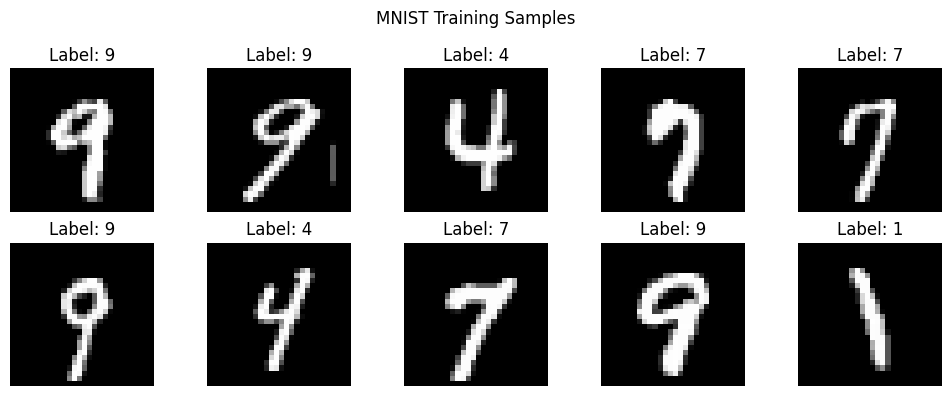

In [28]:
# [4] 손글씨 이미지 샘플 10개 확인
sample_images, sample_labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(sample_images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {sample_labels[i].item()}")
    ax.axis("off")
plt.suptitle("MNIST Training Samples")
plt.tight_layout()
plt.show()

## 5. MLP 모델 정의 — 실험 C

이미지의 `28×28=784`개 픽셀을 펼친 뒤(`Flatten`), 다음 순서로 처리합니다.

`784 → Linear(128) → ReLU → Linear(64) → ReLU → Linear(10)`

- `Linear`: 가중치와 편향을 사용한 선형 변환
- `ReLU`: 비선형 활성화 함수
- **출력 10개:** 숫자 0~9에 대응하는 점수(logit). 확률 자체는 아닙니다.

In [29]:
# [5] MLP 구조: 784 → 128 → 64 → 10
model = nn.Sequential(
    nn.Flatten(),           # [배치, 1, 28, 28] → [배치, 784]
    nn.Linear(784, 64),    # 입력층 → 은닉층 1
    nn.ReLU(),              # 비선형 활성화 함수
    nn.Linear(128, 64),     # 은닉층 1 → 은닉층 2
    nn.ReLU(),              # 비선형 활성화 함수
    nn.Linear(64, 10)       # 은닉층 2 → 출력층 (10개 숫자)
).to(device)

print(model)
print("학습할 파라미터 수:", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=64, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Linear(in_features=64, out_features=10, bias=True)
)
학습할 파라미터 수: 59146


## 6. 손실 함수와 최적화 알고리즘

- **CrossEntropyLoss:** 정답 숫자와 모델 출력의 차이를 손실로 계산합니다.
- **Adam:** 역전파로 구한 기울기를 이용해 가중치와 편향을 갱신합니다.

> `CrossEntropyLoss`는 입력으로 **Softmax 이전의 logit**을 받으므로 모델 마지막에 `Softmax`를 추가하지 않습니다.

In [30]:
# [6] 손실 함수 및 최적화 설정
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
epochs = 5

# 매 Epoch 손실/정확도를 그래프로 나타내기 위한 기록
train_losses = []
train_accuracies = []

## 7. 모델 학습

한 미니배치마다 다음 순서로 실행합니다.

1. **순전파**: `outputs = model(images)`
2. **손실 계산**: `loss = loss_fn(outputs, labels)`
3. **기울기 초기화**: `optimizer.zero_grad()`
4. **역전파**: `loss.backward()`
5. **가중치 갱신**: `optimizer.step()`

In [31]:
# [7] 5 Epoch 학습 및 손실/정확도 기록
for epoch in range(epochs):
    model.train()  # 학습 모드
    total_loss = 0.0
    correct = 0

    for images, labels in train_loader:
        # 데이터를 GPU 또는 CPU로 이동
        images = images.to(device)
        labels = labels.to(device)

        # (1) 순전파: 예측 점수 계산
        outputs = model(images)

        # (2) 손실 함수 계산
        loss = loss_fn(outputs, labels)

        # (3) 이전 배치의 기울기 초기화
        optimizer.zero_grad()

        # (4) 역전파: 각 가중치의 기울기 계산
        loss.backward()

        # (5) 학습: 가중치와 편향 갱신
        optimizer.step()

        # 이번 배치의 결과를 누적
        total_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)  # 가장 큰 점수의 숫자 선택
        correct += (predictions == labels).sum().item()

    # 이번 Epoch의 평균 손실 및 학습 정확도
    avg_loss = total_loss / len(train_dataset)
    accuracy = correct / len(train_dataset)
    train_losses.append(avg_loss)
    train_accuracies.append(accuracy)

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Loss: {avg_loss:.4f}, "
        f"Train Accuracy: {accuracy * 100:.2f}%"
    )

RuntimeError: mat1 and mat2 shapes cannot be multiplied (64x64 and 128x64)

## 8. 테스트 데이터로 최종 평가

학습에 사용하지 않은 **테스트 데이터 10,000장**으로 정확도와 평균 손실을 확인합니다.

In [ ]:
# [8] 학습된 모델을 테스트 데이터로 평가
model.eval()      # 평가 모드
correct = 0
total_test_loss = 0.0

# 테스트에서는 기울기 계산이 필요 없음
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        total_test_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()

test_accuracy = correct / len(test_dataset)
avg_test_loss = total_test_loss / len(test_dataset)

print()
print("========== 최종 테스트 결과 ==========")
print(f"테스트 손실: {avg_test_loss:.4f}")
print(f"테스트 정확도: {test_accuracy * 100:.2f}%")

## 9. 학습 과정 시각화

Epoch에 따라 **학습 손실이 감소하는지**, **학습 정확도가 증가하는지** 관찰합니다.

In [ ]:
# [9] Epoch별 학습 손실과 정확도 그래프
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = range(1, epochs + 1)

axes[0].plot(x, train_losses, marker="o")
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True)

axes[1].plot(x, [v * 100 for v in train_accuracies], marker="o")
axes[1].set_title("Training Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 10. 실제 이미지 예측 결과 확인

테스트 데이터 10장의 **정답(True)**과 **예측(Pred)**을 비교합니다.

In [ ]:
# [10] 손글씨 10장에 대한 모델의 예측 확인
images, labels = next(iter(test_loader))

model.eval()
with torch.no_grad():
    outputs = model(images.to(device))
    predictions = outputs.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(
        f"True: {labels[i].item()} / Pred: {predictions[i].item()}"
    )
    ax.axis("off")

plt.suptitle("MNIST Test Predictions")
plt.tight_layout()
plt.subplots_adjust(hspace=0.5)
plt.show()

In [ ]:
# [10-1] 모델이 가장 높은 확신도로 틀린 이미지 10개 확인
# '오답 확신도' = 모델이 잘못 예측한 숫자에 부여한 Softmax 확률
# 테스트 데이터 전체(10,000장)에서 오답만 골라, 확신도가 높은 순서로 표시

model.eval()
wrong_samples = []

with torch.no_grad():
    for images, labels in test_loader:
        # 이미지와 정답을 모델과 같은 장치로 이동
        images = images.to(device)
        labels = labels.to(device)

        # 모델 출력은 확률이 아닌 점수(logits)
        logits = model(images)

        # Softmax를 적용해 10개 숫자에 대한 확률로 변환
        probabilities = torch.softmax(logits, dim=1)

        # 가장 확률이 높은 숫자와 그 확률 추출
        confidence, predictions = probabilities.max(dim=1)

        # 오답인 이미지의 인덱스만 선택
        wrong_indices = (predictions != labels).nonzero(as_tuple=True)[0]

        for idx in wrong_indices.tolist():
            true_label = labels[idx].item()
            pred_label = predictions[idx].item()
            wrong_samples.append({
                "image": images[idx].cpu(),
                "true": true_label,
                "pred": pred_label,
                "confidence": confidence[idx].item(),
                "true_prob": probabilities[idx, true_label].item()
            })

# 잘못 예측한 숫자에 부여한 확률(확신도)이 높은 순서로 정렬
wrong_samples.sort(key=lambda sample: sample["confidence"], reverse=True)
top_wrong = wrong_samples[:10]

print(f"전체 테스트 이미지: {len(test_dataset):,}장")
print(f"오답 이미지: {len(wrong_samples):,}장")
print(f"오답률: {len(wrong_samples) / len(test_dataset) * 100:.2f}%")

if not top_wrong:
    print("틀린 이미지가 없습니다.")
else:
    fig, axes = plt.subplots(2, 5, figsize=(13, 6))

    for ax in axes.flat:
        ax.axis("off")

    for ax, sample in zip(axes.flat, top_wrong):
        ax.imshow(sample["image"].squeeze(), cmap="gray")
        ax.set_title(
            f'True: {sample["true"]} / Pred: {sample["pred"]}\n'
            f'Wrong conf: {sample["confidence"]:.1%}\n'
            f'True prob: {sample["true_prob"]:.1%}',
            fontsize=10
        )

    plt.suptitle("Top 10 Most Confident Wrong Predictions")
    plt.tight_layout()
    plt.subplots_adjust(hspace=0.5)
    plt.show()
